In [2]:
import sys
import torch

print("Python :", sys.version)
print("PyTorch :", torch.__version__)
print("GPU disponible pour PyTorch :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

!nvidia-smi

Python : 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch : 2.11.0+cu130
GPU disponible pour PyTorch : True
GPU : Tesla T4
Thu Nov  5 10:47:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |
|      

In [3]:
import os
import subprocess
from getpass import getpass
from pathlib import Path

def clone_parkvision():
    project = Path("/content/ParkVision")

    if project.exists():
        print("Le dossier existe déjà. Envoie-moi ce message.")
        return

    token = getpass("Colle ton jeton GitHub ici : ").strip()

    # Le jeton est transmis temporairement à Git.
    # Il n'est pas ajouté à l'URL du dépôt.
    helper = (
        '!f() { printf "%s\\n" "username=x-access-token" '
        '"password=$PARKVISION_GH_TOKEN"; }; f'
    )

    result = subprocess.run(
        [
            "git",
            "-c", "credential.helper=",
            "-c", f"credential.helper={helper}",
            "clone",
            "https://github.com/Nourchenne/ParkVision.git",
            str(project),
        ],
        env={
            **os.environ,
            "GIT_TERMINAL_PROMPT": "0",
            "PARKVISION_GH_TOKEN": token,
        },
        capture_output=True,
        text=True,
    )

    del token
    print(result.stdout)
    print(result.stderr)

    if result.returncode == 0:
        print("Projet récupéré avec succès.")
        subprocess.run(
            ["git", "log", "-1", "--oneline"],
            cwd=project,
            check=True,
        )

clone_parkvision()

Colle ton jeton GitHub ici : ··········

Cloning into '/content/ParkVision'...

Projet récupéré avec succès.


In [5]:
%pip install -q --upgrade gdown

In [8]:
from pathlib import Path
from zipfile import ZipFile, is_zipfile

import gdown

file_id = "1pU87rgaUDqHfpjdNjTZaioYKwgIlqxbg"
archive = Path("/content/ParkVision_raw_drive.zip")

if not is_zipfile(archive):
    print("Téléchargement de ParkVision depuis Google Drive…")
    result = gdown.download(id=file_id, output=str(archive), quiet=False)
    if result is None or not is_zipfile(archive):
        raise RuntimeError("Impossible de récupérer le ZIP. Vérifie le message de gdown.")
else:
    print("Archive déjà présente dans Colab.")

print(f"Taille reçue : {archive.stat().st_size / 1024**3:.2f} Go")
print("Vérification du contenu en cours…")

with ZipFile(archive) as zipped:
    damaged = zipped.testzip()
    if damaged:
        raise RuntimeError(f"Fichier endommagé : {damaged}")

print("Archive vérifiée : aucune erreur détectée.")

Téléchargement de ParkVision depuis Google Drive…


Downloading...
From (original): https://drive.google.com/uc?id=1pU87rgaUDqHfpjdNjTZaioYKwgIlqxbg
From (redirected): https://drive.google.com/uc?id=1pU87rgaUDqHfpjdNjTZaioYKwgIlqxbg&confirm=t&uuid=c8a7f4f6-3853-4188-ab85-27608fdc2609
To: /content/ParkVision_raw_drive.zip
100%|██████████| 1.79G/1.79G [00:18<00:00, 95.7MB/s]


Taille reçue : 1.66 Go
Vérification du contenu en cours…
Archive vérifiée : aucune erreur détectée.


In [9]:
from pathlib import Path
from zipfile import ZipFile

project = Path("/content/ParkVision")
archive = Path("/content/ParkVision_raw_drive.zip")

if not (project / "dvc.yaml").is_file():
    raise FileNotFoundError("Le dépôt ParkVision est introuvable.")

print("Extraction en cours…", flush=True)

with ZipFile(archive) as zipped:
    zipped.extractall(project / "data")

print("Extraction terminée.")

expected = {"train": 8691, "valid": 2483, "test": 1242}

for split, count in expected.items():
    folder = project / "data" / "raw" / split
    images = {p.stem for p in (folder / "images").glob("*.jpg")}
    labels = {p.stem for p in (folder / "labels").glob("*.txt")}

    print(f"{split} : {len(images)} images | {len(labels)} annotations")

    if len(images) != count or images != labels:
        raise ValueError(f"Nombre ou correspondance incorrecte dans {split}.")

print("Données brutes extraites : nombres et correspondances corrects.")

Extraction en cours…
Extraction terminée.
train : 8691 images | 8691 annotations
valid : 2483 images | 2483 annotations
test : 1242 images | 1242 annotations
Données brutes extraites : nombres et correspondances corrects.


In [10]:
%pip install -q dvc

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [11]:
%cd /content/ParkVision

import subprocess
import sys

def run_dvc(*args):
    result = subprocess.run(
        [sys.executable, "-m", "dvc", *args],
        capture_output=True,
        text=True,
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    result.check_returncode()

run_dvc("--version")
run_dvc("status", "data/raw.dvc")

/content/ParkVision
3.67.1

data/raw.dvc:
	changed outs:
		not in cache:       data/raw



In [12]:
import subprocess
import sys
import yaml
from pathlib import Path

project = Path("/content/ParkVision")
reference = project / "data/raw.dvc"
before = yaml.safe_load(reference.read_text())

def dvc_command(*args):
    result = subprocess.run(
        [sys.executable, "-m", "dvc", *args],
        cwd=project,
        input="n\n",  # Refuser toute confirmation de changement des données
        capture_output=True,
        text=True,
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    result.check_returncode()

print("Vérification et mise en cache des données…", flush=True)
dvc_command("commit", "data/raw.dvc")

after = yaml.safe_load(reference.read_text())
if before != after:
    raise RuntimeError("La référence DVC a changé : arrêter ici pour vérifier.")

print("Référence DVC inchangée. Reconstruction du découpage…", flush=True)
dvc_command("repro", "prepare_yolo")

print("État final :")
dvc_command("status")

Vérification et mise en cache des données…

Référence DVC inchangée. Reconstruction du découpage…
'data/raw.dvc' didn't change, skipping
Running stage 'prepare_split':
> python src/data/prepare_split.py
train : 69 jours | 8613 images
valid : 19 jours | 2500 images
test : 10 jours | 1029 images
Total retenu : 12142 images | Exclues : 274

Running stage 'prepare_yolo':
> python src/data/prepare_yolo.py
train : 8613 images
valid : 2500 images
test : 1029 images
Fichiers YOLO créés dans data/processed/yolo
Use `dvc push` to send your updates to remote storage.

État final :
Data and pipelines are up to date.



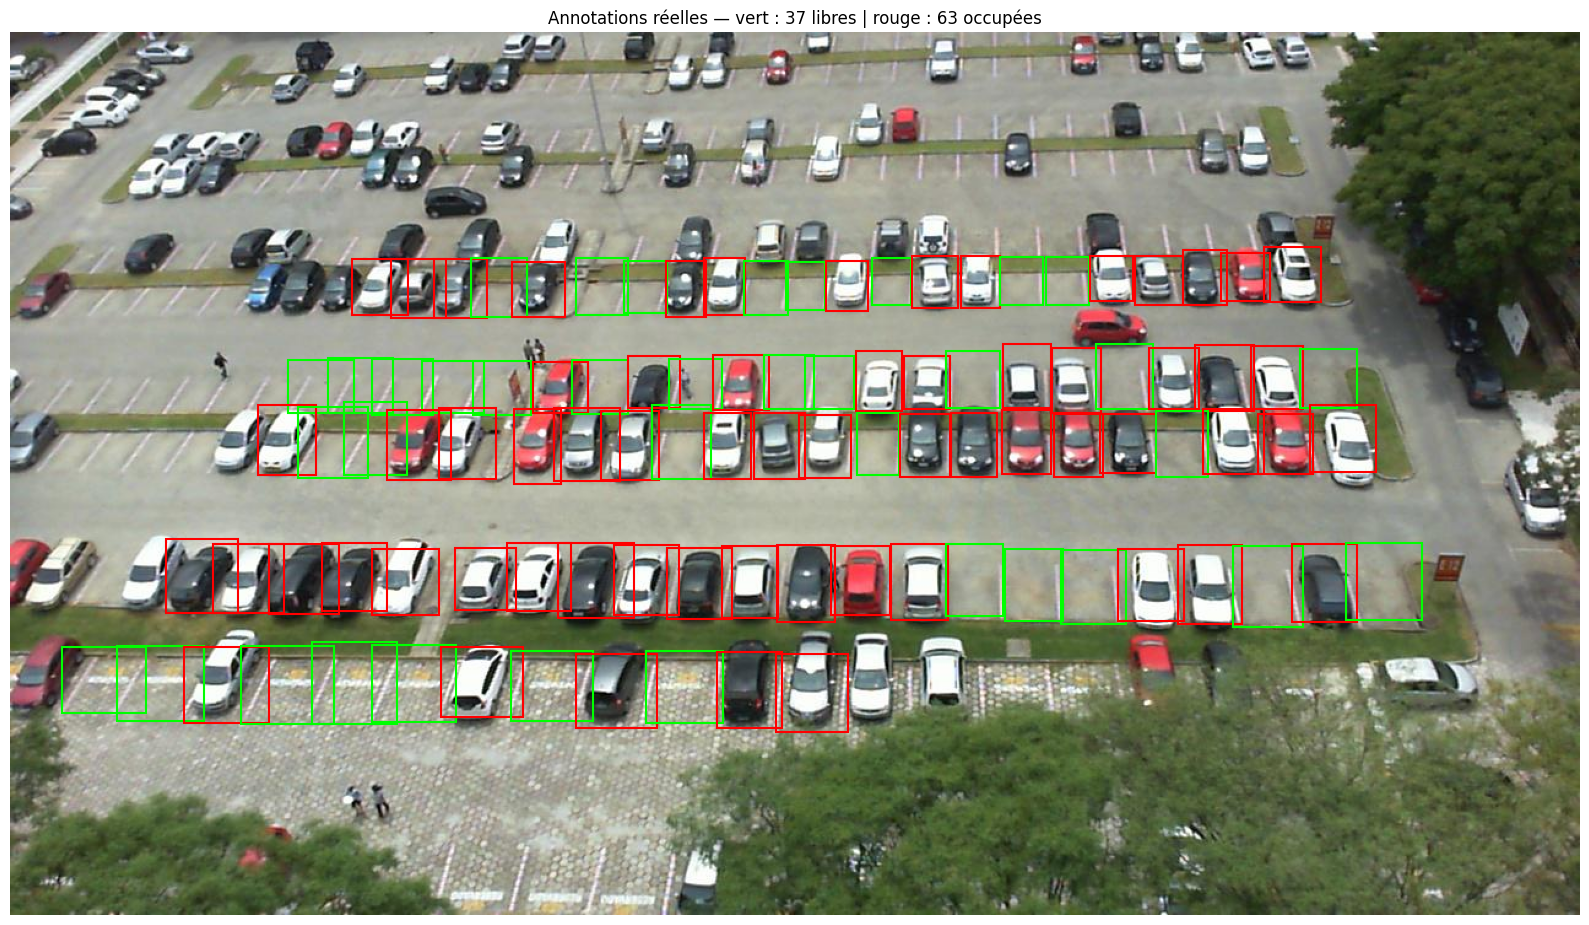

Image : 2012-11-08_12_05_41_jpg.rf.eb4a2b1f976c1cdac96182d98c8ac593.jpg


In [ ]:
import csv
import random
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

project = Path("/content/ParkVision")
manifest = project / "data/processed/split_manifest.csv"

with manifest.open(encoding="utf-8", newline="") as file:
    rows = [row for row in csv.DictReader(file) if row["split"] == "train"]

row = random.Random(42).choice(rows)
image_path = project / row["image"]
label_path = image_path.parent.parent / "labels" / f"{image_path.stem}.txt"

with Image.open(image_path) as source:
    picture = source.convert("RGB")

width, height = picture.size
fig, ax = plt.subplots(figsize=(16, 10))
ax.imshow(picture)

colors = {0: "lime", 1: "red"}
counts = {0: 0, 1: 0}

for line in label_path.read_text(encoding="utf-8-sig").splitlines():
    if not line.strip():
        continue

    cls, cx, cy, bw, bh = map(float, line.split())
    cls = int(cls)
    counts[cls] += 1

    x = (cx - bw / 2) * width
    y = (cy - bh / 2) * height

    ax.add_patch(Rectangle(
        (x, y), bw * width, bh * height,
        linewidth=1.5, edgecolor=colors[cls], facecolor="none"
    ))

ax.set_title(
    f"Annotations réelles — vert : {counts[0]} libres | "
    f"rouge : {counts[1]} occupées"
)
ax.axis("off")
plt.tight_layout()
plt.show()

print("Image :", image_path.name)

In [ ]:
import subprocess

result = subprocess.run(
    ["git", "diff", "--", "dvc.lock"],
    cwd="/content/ParkVision",
    capture_output=True,
    text=True,
    check=True,
)
print(result.stdout or "Aucune modification de dvc.lock.")

Aucune modification de dvc.lock.


In [ ]:
import os
import subprocess
from getpass import getpass
from pathlib import Path

project = Path("/content/ParkVision")

def run_command(args, **kwargs):
    result = subprocess.run(
        args,
        cwd=project,
        capture_output=True,
        text=True,
        **kwargs,
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    result.check_returncode()

def update_project():
    token = getpass("Jeton GitHub : ").strip()

    helper = (
        '!f() { printf "%s\\n" "username=x-access-token" '
        '"password=$PARKVISION_GH_TOKEN"; }; f'
    )

    run_command(
        [
            "git",
            "-c", "credential.helper=",
            "-c", f"credential.helper={helper}",
            "fetch", "origin", "main",
        ],
        env={
            **os.environ,
            "GIT_TERMINAL_PROMPT": "0",
            "PARKVISION_GH_TOKEN": token,
        },
    )
    del token

    run_command([
        "git", "stash", "push",
        "-m", "Sauvegarde du verrou DVC Colab avant synchronisation",
        "--", "dvc.lock",
    ])
    run_command(["git", "merge", "--ff-only", "FETCH_HEAD"])
    run_command(["git", "log", "-1", "--oneline"])

update_project()

Jeton GitHub : ··········

From https://github.com/Nourchenne/ParkVision
 * branch            main       -> FETCH_HEAD

No local changes to save

Already up to date.

4a1944b Ajouter l'entraînement et le transfert MLflow



In [ ]:
import sys

run_command([
    sys.executable, "-m", "dvc", "repro", "prepare_yolo"
])

run_command(["git", "diff", "--", "dvc.lock"])
run_command([sys.executable, "-m", "dvc", "status"])

'data/raw.dvc' didn't change, skipping
Stage 'prepare_split' didn't change, skipping
Stage 'prepare_yolo' didn't change, skipping
Data and pipelines are up to date.


Data and pipelines are up to date.



In [13]:
%cd /content/ParkVision
%pip install -q -r requirements-training.txt

/content/ParkVision


In [14]:
import sys
import torch
import ultralytics
import mlflow

print("Python :", sys.version.split()[0])
print("PyTorch :", torch.__version__)
print("Ultralytics :", ultralytics.__version__)
print("MLflow :", mlflow.__version__)
print("CUDA disponible :", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU indisponible. Vérifie que Colab utilise un environnement GPU."
    )

print("GPU :", torch.cuda.get_device_name(0))

# Vérifier que le GPU peut réellement effectuer un calcul.
with torch.no_grad():
    a = torch.randn(256, 256, device="cuda")
    b = a @ a.T
    torch.cuda.synchronize()
    assert torch.isfinite(b).all().item(), "Résultat GPU invalide."

del a, b
torch.cuda.empty_cache()

print("Calcul sur le GPU : réussi.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python : 3.13.16
PyTorch : 2.11.0+cu130
Ultralytics : 8.4.201
MLflow : 3.17.2
CUDA disponible : True
GPU : Tesla T4
Calcul sur le GPU : réussi.


In [15]:
from pathlib import Path
from importlib.metadata import version
import json
import platform
import subprocess
import torch
import yaml

project = Path("/content/ParkVision")
config_dir = project / "configs"
config_dir.mkdir(exist_ok=True)

# Versions des outils à réutiliser pour les expériences du groupe.
packages = ["ultralytics", "mlflow", "dvc", "PyYAML"]
requirements = "\n".join(
    f"{package}=={version(package)}" for package in packages
) + "\n"

(project / "requirements-training.txt").write_text(
    requirements, encoding="utf-8", newline="\n"
)

# Informations sur l'environnement Colab utilisé.
environment = {
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "cuda_pytorch": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
    "git_commit": subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=project,
        text=True,
    ).strip(),
}

(config_dir / "environment_colab.json").write_text(
    json.dumps(environment, indent=2) + "\n",
    encoding="utf-8",
    newline="\n",
)

# Configuration de ton expérience A.
config = {
    "model": "yolov8n.pt",
    "data": "data/processed/yolo/data.yaml",
    "epochs": 50,
    "patience": 10,
    "imgsz": 640,
    "batch": 16,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "lrf": 0.01,
    "seed": 42,
    "deterministic": True,
    "device": 0,
    "workers": 2,
    "cache": False,
    "amp": True,
    "save": True,
    "plots": True,
    "project": "runs/detect",
    "name": "A_yolov8n_baseline",
    "exist_ok": False,
}

config_path = config_dir / "train_a.yaml"
config_path.write_text(
    yaml.safe_dump(config, sort_keys=False),
    encoding="utf-8",
    newline="\n",
)

print("Versions enregistrées :")
print(requirements)
print("Configuration créée :", config_path)
print("Aucun entraînement lancé.")

Versions enregistrées :
ultralytics==8.4.201
mlflow==3.17.2
dvc==3.67.1
PyYAML==6.0.3

Configuration créée : /content/ParkVision/configs/train_a.yaml
Aucun entraînement lancé.


In [ ]:
from pathlib import Path
import mlflow
from ultralytics import settings

settings.update({"mlflow": False})

tracking_dir = Path("/content/parkvision_tracking")
tracking_dir.mkdir(parents=True, exist_ok=True)

artifact_dir = tracking_dir / "artifacts"
artifact_dir.mkdir(exist_ok=True)

database = tracking_dir / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{database.as_posix()}")

experiment_name = "ParkVision"

experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment is None:
    mlflow.create_experiment(
        name=experiment_name,
        artifact_location=artifact_dir.as_uri(),
    )

mlflow.set_experiment(experiment_name)

print("Expérience :", experiment_name)
print("Base MLflow :", database)
print("Fichiers des expériences :", artifact_dir)
print("Suivi Colab configuré. Aucun entraînement lancé.")

2026/11/05 10:04:35 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/05 10:04:35 INFO mlflow.store.db.utils: Updating database tables


Expérience : ParkVision
Base MLflow : /content/parkvision_tracking/mlflow.db
Fichiers des expériences : /content/parkvision_tracking/artifacts
Suivi Colab configuré. Aucun entraînement lancé.


In [ ]:
from pathlib import Path
import subprocess
import sys
import torch

project = Path("/content/ParkVision")
script = project / "src/models/train.py"

if not script.is_file():
    raise FileNotFoundError("Le script manque. Vérifie la version du dépôt dans Colab.")
if not torch.cuda.is_available():
    raise RuntimeError("Le GPU est indisponible dans cette session Colab.")

print("GPU utilisé :", torch.cuda.get_device_name(0), flush=True)

subprocess.run(
    [sys.executable, str(script), "--config", "configs/train_a.yaml", "--smoke"],
    cwd=project,
    check=True,
)

GPU utilisé : Tesla T4


CompletedProcess(args=['/usr/bin/python3', '/content/ParkVision/src/models/train.py', '--config', 'configs/train_a.yaml', '--smoke'], returncode=0)

In [ ]:
from pathlib import Path
from zipfile import ZipFile
import csv
import json
from google.colab import files

exports = Path("/content/ParkVision/exports")
archives = list(exports.glob("A_yolov8n_baseline_smoke_*.zip"))
if not archives:
    raise FileNotFoundError("Aucun ZIP de l’essai court trouvé dans le dossier exports.")

archive = max(archives, key=lambda p: p.stat().st_mtime)

with ZipFile(archive) as z:
    meta = json.loads(z.read("metadata.json"))
    print("Archive :", archive.name)
    print("Statut MLflow :", meta["status"])

    if meta["status"] != "FINISHED":
        raise RuntimeError("Vérifie le statut du run avant de continuer.")

    rows = list(csv.DictReader(
        z.read("artifacts/training/results.csv").decode("utf-8-sig").splitlines()
    ))
    last = {k.strip(): v.strip() for k, v in rows[-1].items()}
    print("Époque :", last["epoch"])
    for key, value in last.items():
        if key.startswith("metrics/"):
            print(key, "=", value)

    weights = z.getinfo("artifacts/training/weights/best.pt")
    print(f"Modèle best.pt : {weights.file_size / 1024**2:.1f} Mo")

files.download(str(archive))

Archive : A_yolov8n_baseline_smoke_5acac6a0d74648dbb42b2a075dea00fa.zip
Statut MLflow : FINISHED
Époque : 1
metrics/precision(B) = 0.11316
metrics/recall(B) = 0.11765
metrics/mAP50(B) = 0.06544
metrics/mAP50-95(B) = 0.01684
Modèle best.pt : 6.2 Mo


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%cd /content/ParkVision
!python -u src/models/train.py --config configs/train_a.yaml

/content/ParkVision
train : 8613 images
valid : 2500 images
test : 1029 images
2026/11/05 11:13:04 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/05 11:13:04 INFO mlflow.store.db.utils: Updating database tables
New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ParkVision/runs/datasets/fa17bf3133fd431ca976912373b88181/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None